<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/MNIST_classification_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. 데이터 불러오기
digits = datasets.load_digits()

(1797, 8, 8)
[178 182 177 183 181 182 181 179 174 180]


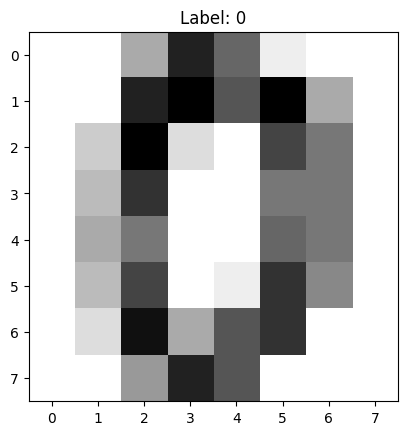

In [2]:
# 2. 데이터 확인
print(digits.images.shape)
print(np.bincount(digits.target))

plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation='nearest')
plt.title(f"Label: {digits.target[0]}")
plt.show()

In [3]:
# 3. 입력 / 정답 분리
n_samples = len(digits.images)
X = digits.images.reshape((n_samples, -1))   # 8x8 이미지를 한 줄(64칸)로 펼침 → Dense 층에 넣기 위해
y = digits.target                            # 정답: 0~9 숫자

# 4. 학습 / 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. 데이터 정규화
# 픽셀값이 0(흰색)~16(검은색) 범위라서 16으로 나눠 0~1로 맞춤
X_train = X_train / 16.0
X_test = X_test / 16.0

# 6. 정답 원-핫 인코딩
# 숫자가 0~9로 10종류 → softmax 출력(10칸)과 모양을 맞추기 위해 정답도 10칸짜리로 바꿈
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=10)
print(y_train[0], "→", y_train_oh[0])

5 → [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [4]:
# 7. 모델 생성
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(64,)))                 # 입력: 픽셀 64개
model.add(tf.keras.layers.Dense(64, activation="relu"))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))    # 다중 분류: 숫자 0~9 각각의 확률 (합 = 1)

# 8. 모델 설정
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [5]:
# 9. 모델 구조 출력
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# 10. 모델 학습
history = model.fit(X_train, y_train_oh, epochs=50, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3499 - loss: 2.1190 - val_accuracy: 0.5312 - val_loss: 1.9074
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6701 - loss: 1.6346 - val_accuracy: 0.7465 - val_loss: 1.3744
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8346 - loss: 1.0648 - val_accuracy: 0.8403 - val_loss: 0.8930
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9034 - loss: 0.6476 - val_accuracy: 0.8819 - val_loss: 0.5732
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9208 - loss: 0.4289 - val_accuracy: 0.8889 - val_loss: 0.4511
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9356 - loss: 0.3194 - val_accuracy: 0.9271 - val_loss: 0.3431
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9469 - loss: 0.2545 - val_accuracy: 0.9201 - val_loss: 0.3129
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9495 - loss: 0.2100 - val_accuracy: 0.9340 - val_loss

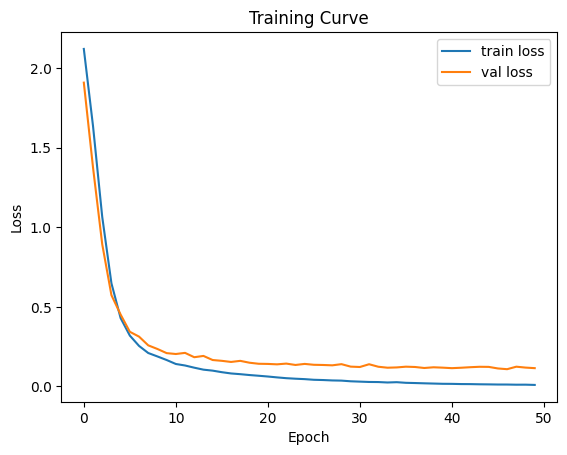

In [7]:
# 11. 학습 곡선 시각화
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Curve")
plt.show()

In [8]:
# 12. 테스트 데이터 예측
y_prob = model.predict(X_test)             # 각 숫자(0~9)일 확률 10개
y_pred = np.argmax(y_prob, axis=1)         # 확률이 가장 큰 칸의 번호 = 예측한 숫자

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


In [9]:
# 13. 성능 평가
print("Accuracy =", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy = 0.9805555555555555

Confusion Matrix
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 35  0  0  0  0  1  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 36  0  1  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  2  0  0  0  0  0  0 33  0]
 [ 0  0  0  0  0  0  0  1  0 35]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      0.97      0.99        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       0.97      0.97      0.97        36
           7       0.97      1.00      0.99        36
           8       0.97      0.94      0.96        35
           9       1.00      0.97      0.99        36

  

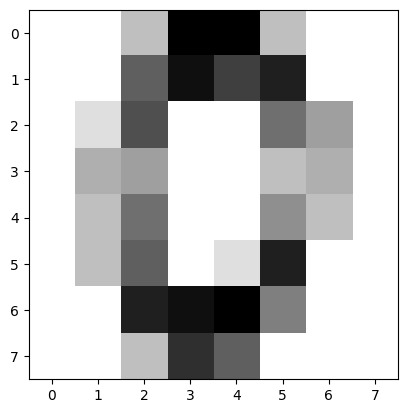

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
예측: 0  / 정답: 0


In [10]:
# 14. 이미지 한 장 예측해보기
plt.imshow(X_test[10].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

prob = model.predict(X_test[10].reshape(1, -1))   # 한 장만 넣을 때도 (1, 64) 모양으로 맞춰야 함
print("예측:", np.argmax(prob), " / 정답:", y_test[10])

틀린 개수: 7


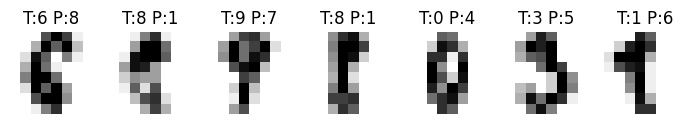

In [11]:
# 15. 틀린 이미지 확인
wrong = np.where(y_pred != y_test)[0]      # 예측과 정답이 다른 위치
print("틀린 개수:", len(wrong))

plt.figure(figsize=(10, 3))
for i, idx in enumerate(wrong[:8]):
    plt.subplot(1, 8, i + 1)
    plt.imshow(X_test[idx].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
    plt.title(f"T:{y_test[idx]} P:{y_pred[idx]}")   # T = 정답, P = 예측
    plt.axis("off")
plt.show()